# **MÓDULO 13**
# Projeto - Fundamentos da Descoberta de Dados

Nesse projeto trabalharemos com a base de dados de produtos de um supermercado do Chile.
A ideia é aplicar estatística descritiva, visualizações de dados e organizar o código para publicação no GitHub.

**Escopo:** os registros descrevem produtos, preços e descontos; não há data, quantidade vendida ou faturamento.
Portanto, contagens representam **registros da base**, e não vendas realizadas.

**Como executar:** extraia o pacote completo e abra este notebook na pasta do projeto.
O CSV e `visualizacoes.py` precisam estar na mesma pasta do notebook. Execute as células na ordem.
As saídas já estão preenchidas; os gráficos também serão gravados na pasta `graficos/`.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from visualizacoes import br, boxplot_precos, barras_desconto, treemap_desconto

# No Jupyter, display renderiza as tabelas. No script, o fallback imprime os dados.
try:
    from IPython.display import display
except ImportError:
    if "display" not in globals():
        def display(objeto):
            print(objeto.to_string() if isinstance(objeto, pd.DataFrame) else objeto)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.float_format", br)
GRAFICOS = Path("graficos")
RESULTADOS = Path("resultados")
GRAFICOS.mkdir(exist_ok=True)
RESULTADOS.mkdir(exist_ok=True)


Faça a leitura dos dados do arquivo CSV.

**Ajuste necessário:** o arquivo anexado usa **vírgula** como delimitador. A célula original do modelo
usava `;`, o que reuniria todos os campos em uma única coluna. O nome do CSV foi simplificado no pacote,
sem alterar seus dados.


In [2]:
arquivo = Path("MODULO7_PROJETOFINAL_BASE_SUPERMERCADO.csv")
if not arquivo.exists():
    candidatos = sorted(Path(".").glob("*SUPERMERCADO*.csv*"))
    if len(candidatos) != 1:
        raise FileNotFoundError("Coloque o CSV do supermercado na pasta do notebook.")
    arquivo = candidatos[0]

df = pd.read_csv(arquivo, sep=",", encoding="utf-8")
colunas_esperadas = {"title", "Marca", "Preco_Normal", "Preco_Desconto", "Preco_Anterior", "Desconto", "Categoria"}
if not colunas_esperadas.issubset(df.columns):
    raise ValueError("O CSV não contém as colunas esperadas; confira o delimitador.")
colunas_numericas = ["Preco_Normal", "Preco_Desconto", "Preco_Anterior", "Desconto"]
df[colunas_numericas] = df[colunas_numericas].apply(pd.to_numeric, errors="raise")
print(f"Base carregada: {len(df)} registros, {df.shape[1]} colunas e {df['Categoria'].nunique()} categorias.")
display(df.head(10))


Base carregada: 1107 registros, 7 colunas e 7 categorias.


,title,Marca,Preco_Normal,Preco_Desconto,Preco_Anterior,Desconto,Categoria
0,"Pack 12 un, Leche extra proteína 1 L",Loncoleche,19788,0,0,0,lacteos
1,"Pack 12 un, Leche chocolate receta original 1 L",Soprole,18228,0,0,0,lacteos
2,"Pack 12 un, Leche semidescremada chocolate 1 L",Soprole,18228,0,0,0,lacteos
3,"Pack 12 un, Leche semidescremada frutilla 1 L",Soprole,18228,0,0,0,lacteos
4,"Pack 12 un, Leche sin lactosa chocolate 1 L",Loncoleche,17988,0,0,0,lacteos
5,"Pack 12 un, Leche sin lactosa frutilla 1 L",Loncoleche,17988,0,0,0,lacteos
6,"Pack 12 un, Leche saborizada light chocolate 1 L",Loncoleche,17988,0,0,0,lacteos
7,"Pack 12 un, Leche saborizada frutilla 1 L",Colun,17388,0,0,0,lacteos
8,"Pack 12 un, Leche saborizada vainilla 1 L",Colun,17388,0,0,0,lacteos
9,"Pack 12 un, Leche saborizada manjar 1 L",Colun,17388,0,0,0,lacteos


## Dicionário e critérios da análise

| Campo | Significado |
|---|---|
| `title` | Nome do produto |
| `Marca` | Marca do produto |
| `Preco_Normal` | Preço normal informado |
| `Preco_Desconto` | Preço com desconto informado |
| `Preco_Anterior` | Preço anterior informado |
| `Desconto` | Valor absoluto de desconto registrado |
| `Categoria` | Categoria original, em espanhol |

- Todos os cálculos solicitados usam as colunas originais, sem substituir preços, remover zeros ou excluir duplicatas.
- A base tem **1.107 registros**, **7 categorias**, **156 marcas**, nenhum valor ausente (`NaN`) e **2 linhas duplicadas além da primeira ocorrência**.
- Há **294 registros com `Preco_Normal = 0` (26,56%)**. Em 244 deles há preço com desconto positivo; em outros 50, todos os campos de preço são zero.
  Esses zeros não devem ser interpretados automaticamente como produtos gratuitos. Mantê-los atende ao cálculo literal solicitado, mas limita a interpretação econômica.
- A coluna `Desconto` tem **989 zeros** e **118 valores positivos**. Nos 118 positivos, o desconto é igual a `Preco_Anterior - Preco_Desconto`.
  Já 126 registros têm preço com desconto positivo, porém preço anterior e desconto iguais a zero; não há informação suficiente para recalcular seu desconto.
- As médias de desconto incluem os zeros. Não foram calculadas médias apenas dos produtos em promoção.
- Os valores são mantidos na **unidade monetária original**: o CSV não identifica explicitamente a moeda. Não são percentuais nem valores convertidos para reais.
- O desvio padrão é **amostral (`ddof=1`)**, padrão do pandas. A comparação entre média e mediana é feita **dentro de cada categoria**, não contra a mediana global.


In [3]:
verificacao = pd.DataFrame({
    "verificacao": ["Registros", "Categorias", "Marcas", "Células ausentes", "Duplicatas além da primeira",
                    "Preço normal zero", "Desconto zero", "Desconto positivo"],
    "quantidade": [len(df), df["Categoria"].nunique(), df["Marca"].nunique(), int(df.isna().sum().sum()),
                   int(df.duplicated().sum()), int(df["Preco_Normal"].eq(0).sum()),
                   int(df["Desconto"].eq(0).sum()), int(df["Desconto"].gt(0).sum())]
})
display(verificacao)


,verificacao,quantidade
0,Registros,1107
1,Categorias,7
2,Marcas,156
3,Células ausentes,0
4,Duplicatas além da primeira,2
5,Preço normal zero,294
6,Desconto zero,989
7,Desconto positivo,118


# 1 - Traga a média e a mediana dos preços - coluna Preco_Normal - por categoria de produto.
# Identifique as categorias que parecem ter um valor de média abaixo ou acima da mediana.

In [4]:
medias = df.groupby("Categoria")["Preco_Normal"].mean().sort_values(ascending=False)
display(medias.to_frame("media_preco_normal"))


,media_preco_normal
Categoria,
comidas-preparadas,"3.095,04"
lacteos,"2.385,22"
congelados,"2.108,04"
belleza-y-cuidado-personal,"1.783,56"
frutas,"1.724,47"
verduras,"1.343,30"
instantaneos-y-sopas,"765,49"


In [5]:
medianas = df.groupby("Categoria")["Preco_Normal"].median()
resumo = pd.concat([medias.rename("media"), medianas.rename("mediana")], axis=1)
resumo["media_menos_mediana"] = resumo["media"] - resumo["mediana"]
resumo["comparacao"] = np.select(
    [resumo["media"] > resumo["mediana"], resumo["media"] < resumo["mediana"]],
    ["Média acima da mediana", "Média abaixo da mediana"],
    default="Média igual à mediana",
)
display(resumo)


,media,mediana,media_menos_mediana,comparacao
Categoria,,,,
comidas-preparadas,"3.095,04","3.290,00","-194,96",Média abaixo da mediana
lacteos,"2.385,22","989,00","1.396,22",Média acima da mediana
congelados,"2.108,04","1.519,00","589,04",Média acima da mediana
belleza-y-cuidado-personal,"1.783,56","1.569,00","214,56",Média acima da mediana
frutas,"1.724,47","1.195,00","529,47",Média acima da mediana
verduras,"1.343,30","1.180,00","163,30",Média acima da mediana
instantaneos-y-sopas,"765,49","439,00","326,49",Média acima da mediana


**Resposta:** a média é **maior que a mediana** em `lacteos`, `belleza-y-cuidado-personal`,
`congelados`, `frutas`, `instantaneos-y-sopas` e `verduras`.

Apenas em **`comidas-preparadas`** a média (**3.095,04**) fica **abaixo** da mediana (**3.290,00**).
Nenhuma categoria tem média igual à mediana.

Nas seis primeiras categorias, preços altos podem elevar a média em relação ao centro da distribuição.
Essa comparação sugere assimetria, mas não a comprova isoladamente. Em comidas preparadas,
os preços baixos e os zeros reduzem a média: há 10 zeros entre os 46 registros.


# 2 - Traga o desvio padrão por categoria de produto.
# Qual o comportamento da média e mediana nas categorias com maior desvio?

In [6]:
desvios = df.groupby("Categoria")["Preco_Normal"].std(ddof=1).rename("desvio_padrao")
estatisticas = resumo.join(desvios)
estatisticas["quantidade"] = df.groupby("Categoria").size()
estatisticas = estatisticas.sort_values("desvio_padrao", ascending=False)
categoria_maior_desvio = estatisticas["desvio_padrao"].idxmax()
display(estatisticas[["quantidade", "media", "mediana", "desvio_padrao", "comparacao"]])
print(f"Maior desvio padrão: {categoria_maior_desvio} = {br(desvios.max())}.")
estatisticas.to_csv(RESULTADOS / "estatisticas_por_categoria.csv", encoding="utf-8-sig")


,quantidade,media,mediana,desvio_padrao,comparacao
Categoria,,,,,
lacteos,447,"2.385,22","989,00","3.925,82",Média acima da mediana
belleza-y-cuidado-personal,239,"1.783,56","1.569,00","2.210,04",Média acima da mediana
congelados,235,"2.108,04","1.519,00","2.111,54",Média acima da mediana
comidas-preparadas,46,"3.095,04","3.290,00","2.019,91",Média abaixo da mediana
frutas,19,"1.724,47","1.195,00","1.639,15",Média acima da mediana
instantaneos-y-sopas,57,"765,49","439,00","1.170,23",Média acima da mediana
verduras,64,"1.343,30","1.180,00","1.012,70",Média acima da mediana


Maior desvio padrão: lacteos = 3.925,82.


**Lácteos (`lacteos`) apresenta o maior desvio padrão: 3.925,82.** Sua média é **2.385,22**
e a mediana é **989,00**. A média equivale a aproximadamente 2,41 vezes a mediana, sinalizando
que os preços altos têm influência relevante no valor médio. O desvio padrão elevado indica
grande dispersão dos valores absolutos em torno da média.

As duas categorias seguintes também têm média acima da mediana:

| Categoria | Média | Mediana | Desvio padrão |
|---|---:|---:|---:|
| `belleza-y-cuidado-personal` | 1.783,56 | 1.569,00 | 2.210,04 |
| `congelados` | 2.108,04 | 1.519,00 | 2.111,54 |

O conjunto mistura produtos, tamanhos de embalagem e packs. Assim, a dispersão reflete também
essas diferenças; não representa oscilação temporal do preço de um único produto.
Os zeros de `Preco_Normal` também influenciam média, mediana e desvio padrão.


# 3 - Plot um boxplot da distribuição do Preco_Normal para a categoria que você identificou que tem o maior desvio padrão. Como é a distribuição desses dados segundo o boxplot? Você identifica muitos outliers?

Dica: Para trazer apenas os dados da categoria que você deseja você pode usar o df.loc[df['Categoria'] == 'CATEGORIA ESCOLHIDA'

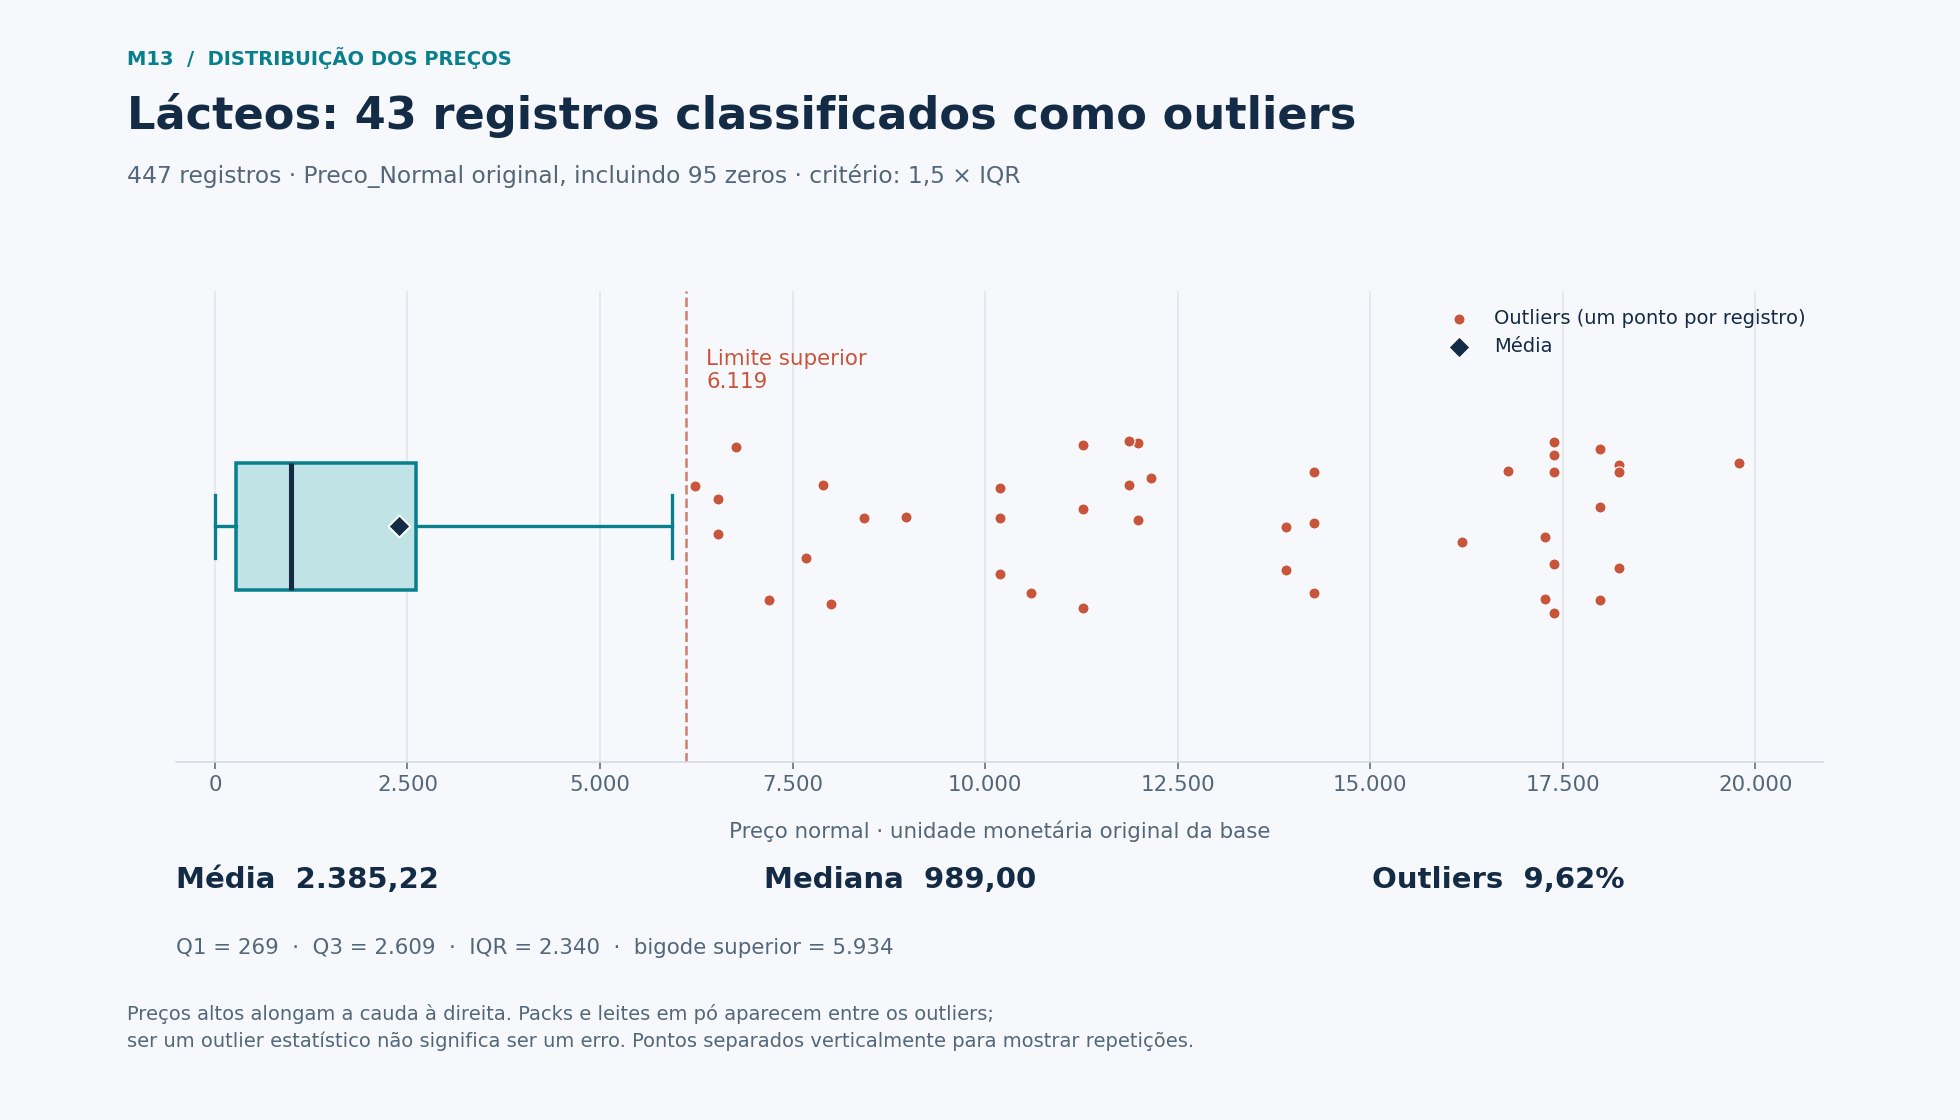

In [7]:
precos_categoria = df.loc[df["Categoria"].eq(categoria_maior_desvio), "Preco_Normal"]
fig_boxplot = boxplot_precos(
    precos_categoria, categoria_maior_desvio, GRAFICOS / "01_boxplot_lacteos.png"
)
plt.show()


### Identificação dos outliers — regra de Tukey

Um registro é classificado como outlier quando está abaixo de `Q1 − 1,5 × IQR`
ou acima de `Q3 + 1,5 × IQR`, sendo `IQR = Q3 − Q1`. Valores exatamente nos limites não são outliers.
Os quartis usam a interpolação linear padrão do pandas, consistente com o boxplot gerado.


In [8]:
q1, q3 = precos_categoria.quantile([0.25, 0.75])
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr
mascara_outlier = (df["Categoria"].eq(categoria_maior_desvio) &
                  ((df["Preco_Normal"] < limite_inferior) | (df["Preco_Normal"] > limite_superior)))
outliers = df.loc[mascara_outlier, ["title", "Marca", "Categoria", "Preco_Normal"]].copy()
outliers.insert(0, "registro_base", outliers.index + 1)
outliers = outliers.sort_values("Preco_Normal", ascending=False, kind="stable")
dentro = precos_categoria.between(limite_inferior, limite_superior)
limites = pd.DataFrame({"medida": ["Q1", "Mediana", "Q3", "IQR", "Limite inferior", "Limite superior",
                                        "Bigode inferior", "Bigode superior"],
                        "valor": [q1, precos_categoria.median(), q3, iqr, limite_inferior, limite_superior,
                                  precos_categoria[dentro].min(), precos_categoria[dentro].max()]})
display(limites)
print(f"Outliers: {len(outliers)} de {len(precos_categoria)} registros ({br(100*len(outliers)/len(precos_categoria))}%).")
with pd.option_context("display.max_rows", None):
    display(outliers.reset_index(drop=True))
outliers.to_csv(RESULTADOS / "outliers_lacteos.csv", index=False, encoding="utf-8-sig")


,medida,valor
0,Q1,"269,00"
1,Mediana,"989,00"
2,Q3,"2.609,00"
3,IQR,"2.340,00"
4,Limite inferior,"-3.241,00"
5,Limite superior,"6.119,00"
6,Bigode inferior,"0,00"
7,Bigode superior,"5.934,00"


Outliers: 43 de 447 registros (9,62%).


,registro_base,title,Marca,Categoria,Preco_Normal
0,1,"Pack 12 un, Leche extra proteína 1 L",Loncoleche,lacteos,19788
1,2,"Pack 12 un, Leche chocolate receta original 1 L",Soprole,lacteos,18228
2,3,"Pack 12 un, Leche semidescremada chocolate 1 L",Soprole,lacteos,18228
3,4,"Pack 12 un, Leche semidescremada frutilla 1 L",Soprole,lacteos,18228
4,5,"Pack 12 un, Leche sin lactosa chocolate 1 L",Loncoleche,lacteos,17988
5,6,"Pack 12 un, Leche sin lactosa frutilla 1 L",Loncoleche,lacteos,17988
6,7,"Pack 12 un, Leche saborizada light chocolate 1 L",Loncoleche,lacteos,17988
7,8,"Pack 12 un, Leche saborizada frutilla 1 L",Colun,lacteos,17388
8,9,"Pack 12 un, Leche saborizada vainilla 1 L",Colun,lacteos,17388
9,10,"Pack 12 un, Leche saborizada manjar 1 L",Colun,lacteos,17388


**Leitura do boxplot:** os 50% centrais dos registros estão entre **269,00 (Q1)** e **2.609,00 (Q3)**,
com mediana em **989,00**. O IQR é **2.340,00**, o limite inferior é **−3.241,00** e o superior é **6.119,00**.
Os bigodes chegam a **0,00** e **5.934,00**, os valores observados extremos dentro dos limites.
O limite de Tukey e a ponta do bigode são conceitos diferentes.

Há **43 outliers superiores**, equivalentes a **9,62%** dos 447 registros de lácteos, e nenhum inferior.
Seus preços variam de **6.229,00** a **19.788,00**. São 43 registros, mas apenas **24 preços distintos**;
pontos podem se sobrepor num boxplot convencional. O gráfico separa os pontos verticalmente para evidenciar repetições.

A cauda longa à direita é compatível com a média maior que a mediana. Entre os extremos estão packs
de leite e leites em pó, por exemplo, **“Pack 12 un, Leche extra proteína 1 L” (Loncoleche; 19.788)**
e **“Leche en Polvo Svelty Descremada 800g” (Svelty; 6.229)**.
Isso pode refletir diferenças reais entre embalagens; não justifica excluir esses registros automaticamente.
A lista completa está na tabela acima e em `resultados/outliers_lacteos.csv`.


# 4 - Plote um gráfico de barras onde temos a média de descontos por categoria.

,quantidade,desconto_medio,com_desconto
Categoria,,,
congelados,235,"154,03",60
belleza-y-cuidado-personal,239,"123,08",43
comidas-preparadas,46,"43,48",4
lacteos,447,"17,41",11
frutas,19,"0,00",0
instantaneos-y-sopas,57,"0,00",0
verduras,64,"0,00",0


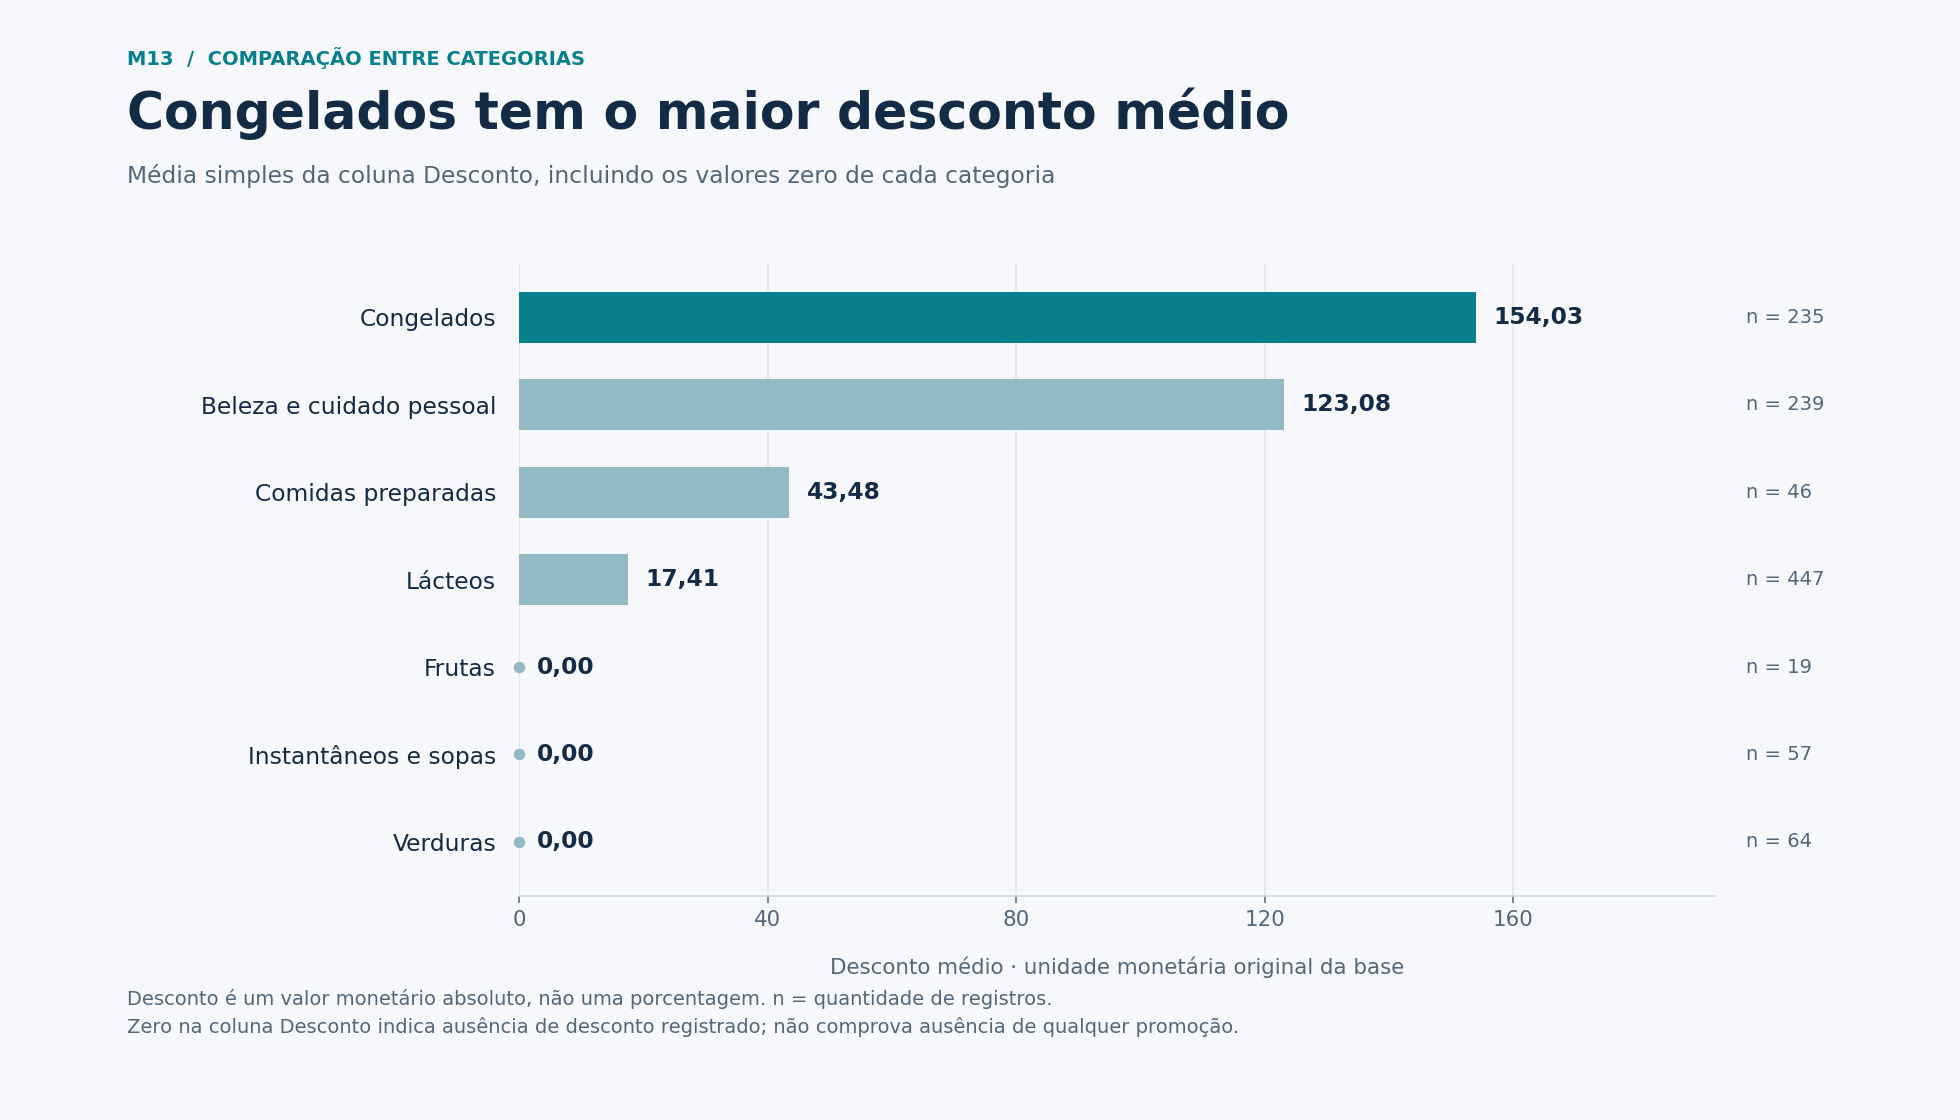

In [9]:
descontos_categoria = df.groupby("Categoria").agg(
    quantidade=("Desconto", "size"),
    desconto_medio=("Desconto", "mean"),
    com_desconto=("Desconto", lambda valores: int(valores.gt(0).sum())),
).sort_values("desconto_medio", ascending=False)
display(descontos_categoria)
fig_barras = barras_desconto(descontos_categoria, GRAFICOS / "02_desconto_por_categoria.png")
plt.show()
descontos_categoria.to_csv(RESULTADOS / "desconto_por_categoria.csv", encoding="utf-8-sig")


**Interpretação:** `congelados` apresenta o maior desconto médio (**154,03**), seguido de
`belleza-y-cuidado-personal` (**123,08**), `comidas-preparadas` (**43,48**) e `lacteos` (**17,41**).
`frutas`, `instantaneos-y-sopas` e `verduras` têm média **zero** na coluna `Desconto`.

Essas médias combinam a frequência de registros com desconto positivo e o tamanho desses descontos.
Não permitem afirmar qual categoria tem o maior desconto percentual, margem, faturamento ou retorno comercial.
A ordem decrescente e as barras horizontais facilitam a comparação dos valores e a leitura dos nomes.


# 5 - Plote um gráfico de mapa interativo agrupando os dados por categoria, marca e trazendo a média de desconto.

**Escolha da visualização:** um **treemap (mapa de árvore)** representa a hierarquia
`Categoria → Marca`. Não se trata de um mapa geográfico: a base não contém localizações ou coordenadas.

A **área** de cada marca representa sua quantidade de registros dentro da categoria;
a **cor** representa a média de `Desconto` dessa combinação. Assim, marcas com média zero também
aparecem. A cor tem a mesma escala em todas as categorias e nos filtros.
Cada média é calculada diretamente nos registros de origem: não somamos médias nem fazemos média simples entre médias de marcas.

O HTML é autocontido, funciona offline e permite filtrar uma categoria, consultar os detalhes de uma marca
por mouse/toque/teclado e voltar à visão geral. Sua geometria é a mesma usada no PNG.
O código de desenho está em `visualizacoes.py` e usa Matplotlib e HTML/SVG, sem bibliotecas web externas.


,Categoria,Marca,quantidade,desconto_medio,com_desconto
78,congelados,Magnum,4,"955,00",4
142,lacteos,Nido,5,"869,80",1
39,belleza-y-cuidado-personal,Oral Fresh,1,"797,00",1
48,belleza-y-cuidado-personal,Rexona Men Clinical,1,"795,00",1
46,belleza-y-cuidado-personal,Rexona Clinical,2,"795,00",2
41,belleza-y-cuidado-personal,Pantene,7,"684,86",6
45,belleza-y-cuidado-personal,Rexona,1,"660,00",1
47,belleza-y-cuidado-personal,Rexona Men,1,"660,00",1
79,congelados,Mega,1,"657,00",1
6,belleza-y-cuidado-personal,BiO,4,"650,00",4


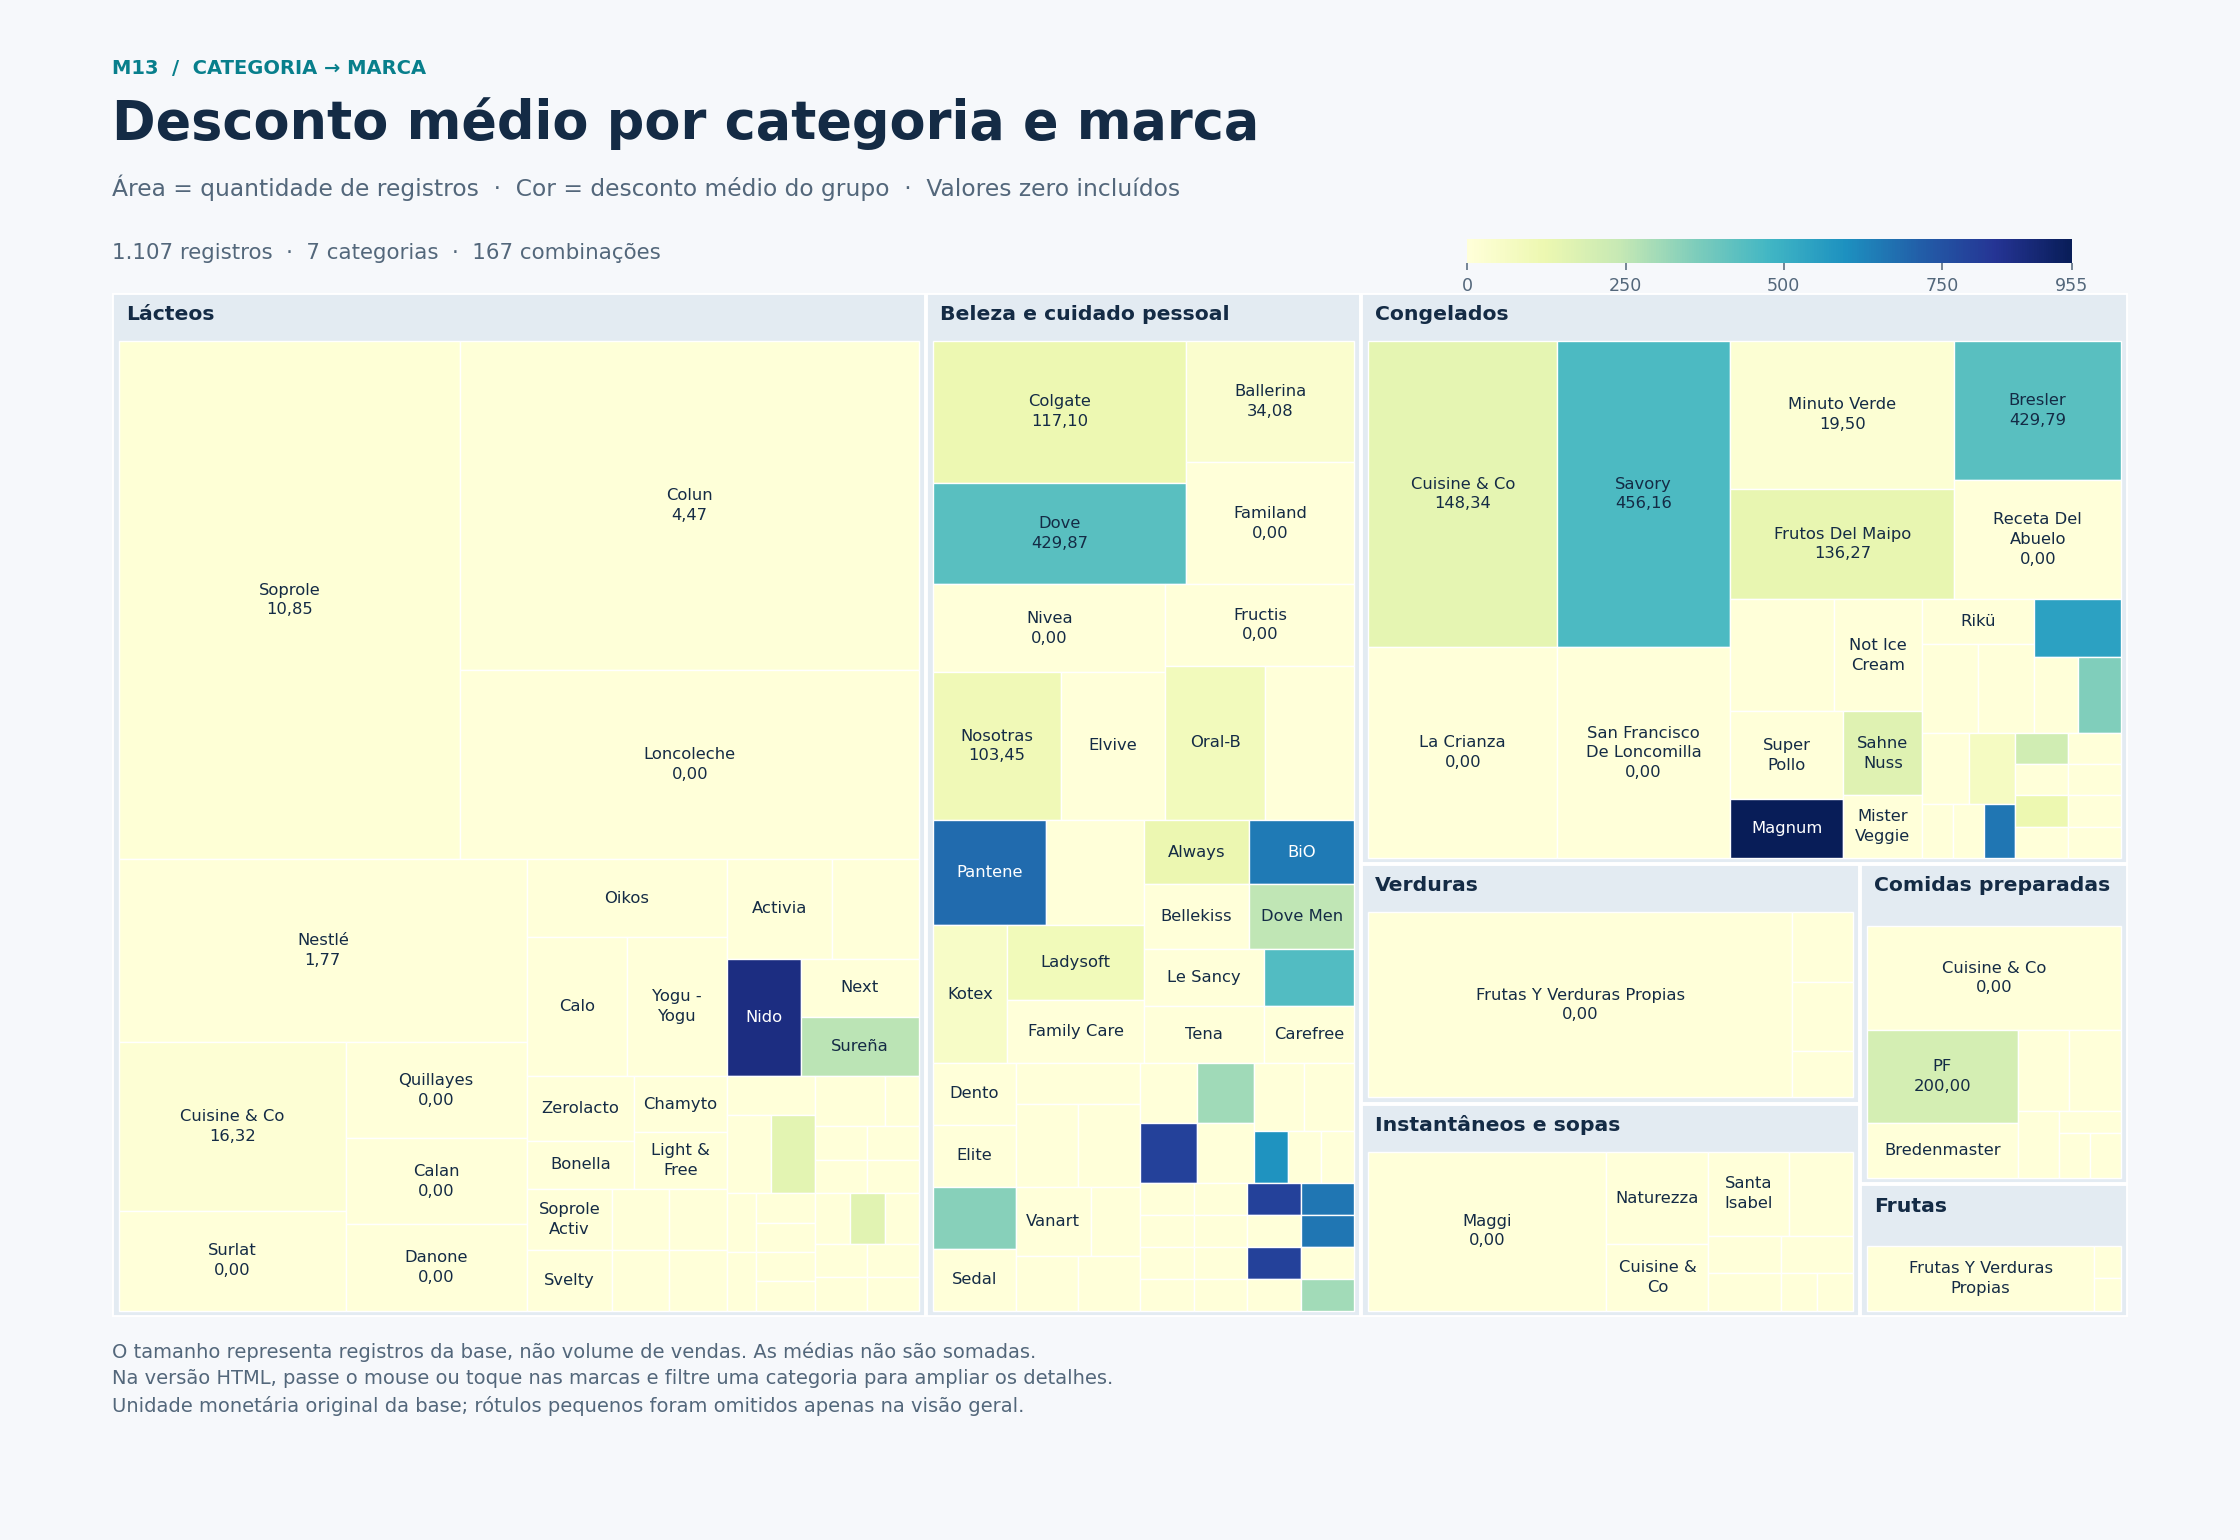

Mapa interativo salvo em graficos/03_mapa_interativo.html. Abra esse arquivo no navegador.


In [10]:
descontos_marca = df.groupby(["Categoria", "Marca"], as_index=False).agg(
    quantidade=("Desconto", "size"),
    desconto_medio=("Desconto", "mean"),
    com_desconto=("Desconto", lambda valores: int(valores.gt(0).sum())),
)
display(descontos_marca.sort_values("desconto_medio", ascending=False).head(10))
fig_mapa = treemap_desconto(
    descontos_marca, descontos_categoria,
    GRAFICOS / "03_mapa_categoria_marca.png",
    GRAFICOS / "03_mapa_interativo.html",
)
plt.show()
descontos_marca.to_csv(RESULTADOS / "desconto_por_categoria_marca.csv", index=False, encoding="utf-8-sig")
print("Mapa interativo salvo em graficos/03_mapa_interativo.html. Abra esse arquivo no navegador.")
# No Jupyter, a célula abaixo incorpora o mesmo HTML; o arquivo funciona também offline.
try:
    from IPython.display import IFrame
    display(IFrame(src="graficos/03_mapa_interativo.html", width="100%", height=1050))
except ImportError:
    pass


**Leitura do mapa:** a combinação `congelados → Magnum` tem a maior média de desconto (**955,00**),
com **4 registros**. `lacteos → Nido` vem em seguida (**869,80**, com **5 registros**).
Assim, uma categoria com média geral baixa, como lácteos, ainda pode conter marcas com média elevada.
Grupos com poucos registros merecem cautela; os valores não demonstram eficácia de promoções nem volume de vendas.


## Verificação complementar: efeito dos preços normais iguais a zero

Esta seção **não substitui** os resultados pedidos; serve para explicitar uma limitação dos dados.
Ao considerar apenas `Preco_Normal > 0`, lácteos continua com o maior desvio padrão.
Porém, em comidas preparadas a média passa a **3.954,78** e a mediana a **3.740,00**:
a relação entre as duas medidas se inverte. Portanto, não seria adequado tratar a conclusão da base original
como uma característica definitiva dos preços reais de mercado.


In [11]:
sensibilidade = df.loc[df["Preco_Normal"].gt(0)].groupby("Categoria")["Preco_Normal"].agg(
    quantidade="size", media="mean", mediana="median", desvio_padrao="std"
).sort_values("desvio_padrao", ascending=False)
sensibilidade["comparacao"] = np.where(sensibilidade["media"] > sensibilidade["mediana"],
                                     "Média acima da mediana", "Média abaixo ou igual à mediana")
display(sensibilidade)
sensibilidade.to_csv(RESULTADOS / "sensibilidade_preco_normal_positivo.csv", encoding="utf-8-sig")


,quantidade,media,mediana,desvio_padrao,comparacao
Categoria,,,,,
lacteos,352,"3.028,96","1.719,50","4.198,57",Média acima da mediana
belleza-y-cuidado-personal,146,"2.919,66","2.179,00","2.162,65",Média acima da mediana
congelados,164,"3.020,67","2.954,00","1.904,48",Média acima da mediana
frutas,19,"1.724,47","1.195,00","1.639,15",Média acima da mediana
comidas-preparadas,36,"3.954,78","3.740,00","1.322,33",Média acima da mediana
instantaneos-y-sopas,37,"1.179,27","689,00","1.276,22",Média acima da mediana
verduras,59,"1.457,14","1.250,00","972,23",Média acima da mediana


## Conclusão e entrega

1. Na coluna original, seis categorias têm média acima da mediana; apenas comidas preparadas apresenta média abaixo.
2. Lácteos tem a maior dispersão e 43 outliers superiores pelo critério de 1,5 × IQR. Packs e diferentes tamanhos de produto ajudam a contextualizar os extremos.
3. Congelados tem o maior desconto médio por categoria. O treemap detalha as diferenças entre marcas e mantém os grupos com média zero visíveis.
4. Os zeros e a ausência de dados de quantidade vendida limitam conclusões sobre preços efetivamente praticados e impacto comercial.

**Arquivos para enviar:** `graficos/01_boxplot_lacteos.png`, `graficos/02_desconto_por_categoria.png`
e `graficos/03_mapa_categoria_marca.png`, além do link do repositório GitHub.
O arquivo `graficos/03_mapa_interativo.html` preserva a interatividade.

**Repositório GitHub:** [mrlnasc/projeto-m13-supermercado](https://github.com/mrlnasc/projeto-m13-supermercado).
Consulte `README.md` para executar o projeto e acessar os gráficos.
